# Notebook 2. Entrenamiento, evaluación y comparación de tres modelos

**Proyecto:** MamaIA – Breast Cancer Wisconsin (Diagnostic).

## Objetivo
Entrenar y comparar K-Nearest Neighbors (KNN), Support Vector Machine (SVM) y Random Forest. Se utiliza la misma codificación (`1 = maligno`, `0 = benigno`), las diez variables medias y una partición estratificada 80/20 con semilla 42.

La búsqueda de hiperparámetros se realiza mediante `GridSearchCV` y validación cruzada estratificada repetida. El escalamiento se integra en los *pipelines* de KNN y SVM para evitar fuga de información.

> Ejecuta todas las celdas en orden. Para mantener la coherencia con MamaIA, el notebook busca `datos.csv`; si no está disponible, utiliza el dataset Wisconsin incluido en scikit-learn.

In [ ]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn

In [ ]:

from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

SEED = 42
FEATURES = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimension"
]

def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", "", texto.lower())

def cargar_dataset():
    """Busca el CSV del repositorio; si no está, usa el mismo dataset Wisconsin de scikit-learn."""
    candidatos = [Path("datos.csv"), Path("../datos.csv"), Path("data/datos.csv")]
    archivo = next((p for p in candidatos if p.exists()), None)

    if archivo:
        bruto = pd.read_csv(archivo)
        # Mapear nombres alternativos a los diez nombres canónicos.
        aliases = {
            "meanradius": "mean radius", "radiome dio": "mean radius",
            "meantexture": "mean texture", "texturamedia": "mean texture",
            "meanperimeter": "mean perimeter", "perimetromedio": "mean perimeter",
            "meanarea": "mean area", "areamedia": "mean area",
            "meansmoothness": "mean smoothness", "suavidadmedia": "mean smoothness",
            "meancompactness": "mean compactness", "compactacionmedia": "mean compactness",
            "meanconcavity": "mean concavity", "concavidadmedia": "mean concavity",
            "meanconcavepoints": "mean concave points", "puntosconcavosmedios": "mean concave points",
            "meansymmetry": "mean symmetry", "simetriamedia": "mean symmetry",
            "meanfractaldimension": "mean fractal dimension", "dimensionfractralmedia": "mean fractal dimension",
            "maligno": "maligno", "diagnostico": "maligno", "diagnosis": "maligno",
            "target": "maligno", "label": "maligno", "class": "maligno"
        }
        renombrar = {}
        for c in bruto.columns:
            k = normalizar(c)
            if k in aliases:
                renombrar[c] = aliases[k]
            elif k == "meanconcavepoints":
                renombrar[c] = "mean concave points"
            elif k == "meanfractaldimension":
                renombrar[c] = "mean fractal dimension"
        df = bruto.rename(columns=renombrar)
        if all(c in df.columns for c in FEATURES) and "maligno" in df.columns:
            X = df[FEATURES].apply(pd.to_numeric, errors="coerce")
            raw_y = df["maligno"]
            if pd.api.types.is_numeric_dtype(raw_y):
                y = pd.to_numeric(raw_y, errors="coerce")
                # En este proyecto, 1 = maligno y 0 = benigno.
                if set(y.dropna().unique()).issubset({0, 1}):
                    y = y.astype(int)
                else:
                    raise ValueError("La etiqueta numérica debe estar codificada como 0=benigno y 1=maligno.")
            else:
                etiquetas = raw_y.astype(str).str.strip().str.lower()
                mapa = {"m": 1, "maligno": 1, "malignant": 1, "b": 0, "benigno": 0, "benign": 0}
                y = etiquetas.map(mapa)
            datos = X.copy()
            datos["maligno"] = y
            datos = datos.dropna()
            return datos[FEATURES], datos["maligno"].astype(int), f"CSV: {archivo}"
        print(f"El archivo {archivo} no contiene las 10 variables y la etiqueta esperadas; se usará el dataset integrado.")

    cancer = load_breast_cancer(as_frame=True)
    X = cancer.data[FEATURES].copy()
    # En scikit-learn: target=0 es maligno y target=1 es benigno.
    y = (cancer.target == 0).astype(int).rename("maligno")
    return X, y, "Breast Cancer Wisconsin Diagnostic (scikit-learn)"

X, y, fuente_datos = cargar_dataset()
df = X.copy()
df["maligno"] = y
print("Fuente:", fuente_datos)
print("Dimensiones:", df.shape)
print("Codificación: 0 = benigno | 1 = maligno")


Fuente: CSV: datos.csv
Dimensiones: (569, 11)
Codificación: 0 = benigno | 1 = maligno


## 1. Separación entrenamiento/prueba
La prueba se reserva para la evaluación final. La búsqueda de hiperparámetros se ejecuta únicamente sobre entrenamiento.

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f'Total: {len(X)} | Entrenamiento: {len(X_train)} | Prueba: {len(X_test)}')
print('Clases en entrenamiento:', y_train.value_counts().sort_index().to_dict())
print('Clases en prueba:', y_test.value_counts().sort_index().to_dict())

Total: 569 | Entrenamiento: 455 | Prueba: 114
Clases en entrenamiento: {0: 285, 1: 170}
Clases en prueba: {0: 72, 1: 42}


## 2. Definición de modelos y espacios de búsqueda
Se evalúan tres algoritmos distintos. KNN y SVM utilizan StandardScaler dentro del pipeline; Random Forest no requiere estandarización.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

modelos = {
    'KNN': (Pipeline([('escalador', StandardScaler()), ('modelo', KNeighborsClassifier())]),
            {'modelo__n_neighbors':[3,5,7,9,11,15], 'modelo__weights':['uniform','distance']}),
    'SVM': (Pipeline([('escalador', StandardScaler()), ('modelo', SVC(probability=True, random_state=SEED))]),
            {'modelo__C':[0.1,1,10,100], 'modelo__kernel':['linear','rbf']}),
    'Random Forest': (Pipeline([('modelo', RandomForestClassifier(random_state=SEED))]),
            {'modelo__n_estimators':[100,300], 'modelo__max_depth':[3,5,None], 'modelo__min_samples_leaf':[1,3]})
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

## 3. Entrenamiento y búsqueda de hiperparámetros
Se optimiza el F1 mediante validación cruzada. También se registra el recall, una métrica especialmente importante cuando la clase positiva representa casos malignos.

In [ ]:
import time
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

resultados = {}
modelos_ajustados = {}
for nombre, (pipeline, grid) in modelos.items():
    inicio = time.time()
    busqueda = GridSearchCV(pipeline, grid, scoring='f1', cv=cv, n_jobs=-1, refit=True)
    busqueda.fit(X_train, y_train)
    modelos_ajustados[nombre] = busqueda.best_estimator_
    resultados[nombre] = {
        'mejores_parametros': busqueda.best_params_,
        'f1_cv_media': busqueda.best_score_,
        'tiempo_segundos': time.time() - inicio
    }
    print(f'\n{nombre}')
    print('Mejores parámetros:', busqueda.best_params_)
    print('F1 CV:', round(busqueda.best_score_, 4))


KNN
Mejores parámetros: {'modelo__n_neighbors': 15, 'modelo__weights': 'uniform'}
F1 CV: 0.9178

SVM
Mejores parámetros: {'modelo__C': 10, 'modelo__kernel': 'rbf'}
F1 CV: 0.9233

Random Forest
Mejores parámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 300}
F1 CV: 0.9211


## 4. Evaluación en el conjunto de prueba
Se calculan exactitud, precisión, sensibilidad (recall), especificidad, F1 y AUC-ROC. La matriz de confusión usa el orden de etiquetas `[0, 1]`: benigno y maligno.

In [ ]:
filas = []
predicciones = {}
for nombre, modelo in modelos_ajustados.items():
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
    especificidad = tn / (tn + fp) if (tn + fp) else 0
    metricas = {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall (sensibilidad)': recall_score(y_test, pred, zero_division=0),
        'Especificidad': especificidad,
        'F1': f1_score(y_test, pred, zero_division=0),
        'AUC-ROC': roc_auc_score(y_test, proba)
    }
    filas.append(metricas)
    predicciones[nombre] = (pred, proba)
    print(f'\n===== {nombre} =====')
    print(classification_report(y_test, pred, target_names=['Benigno','Maligno'], zero_division=0))
    print('Matriz de confusión [[VN, FP], [FN, VP]]:')
    print(confusion_matrix(y_test, pred, labels=[0,1]))

comparacion = pd.DataFrame(filas).set_index('Modelo')
display(comparacion.round(4))


===== KNN =====
              precision    recall  f1-score   support

     Benigno       0.97      0.97      0.97        72
     Maligno       0.95      0.95      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114

Matriz de confusión [[VN, FP], [FN, VP]]:
[[70  2]
 [ 2 40]]

===== SVM =====
              precision    recall  f1-score   support

     Benigno       0.97      0.99      0.98        72
     Maligno       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

Matriz de confusión [[VN, FP], [FN, VP]]:
[[71  1]
 [ 2 40]]

===== Random Forest =====
              precision    recall  f1-score   support

     Benigno       0.95      0.96      0.95        72
     Maligno       0.93      0.90      0.92        42


,Accuracy,Precision,Recall (sensibilidad),Especificidad,F1,AUC-ROC
Modelo,,,,,,
KNN,0.9649,0.9524,0.9524,0.9722,0.9524,0.9901
SVM,0.9737,0.9756,0.9524,0.9861,0.9639,0.9841
Random Forest,0.9386,0.9268,0.9048,0.9583,0.9157,0.9841


## 5. Comparación gráfica de métricas

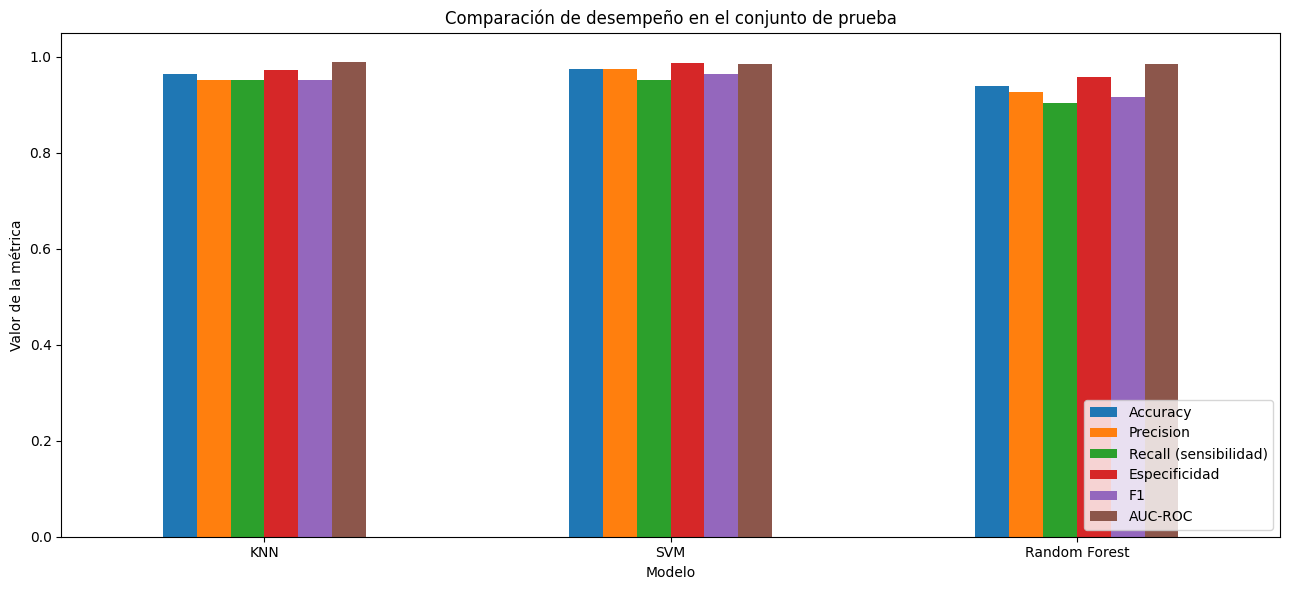

In [ ]:
ax = comparacion[['Accuracy','Precision','Recall (sensibilidad)','Especificidad','F1','AUC-ROC']].plot(
    kind='bar', figsize=(13,6), ylim=(0,1.05), rot=0
)
ax.set_title('Comparación de desempeño en el conjunto de prueba')
ax.set_ylabel('Valor de la métrica'); ax.set_xlabel('Modelo')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 6. Curvas ROC
La curva ROC muestra la relación entre la tasa de verdaderos positivos y la tasa de falsos positivos para distintos umbrales.

<Figure size 800x600 with 0 Axes>

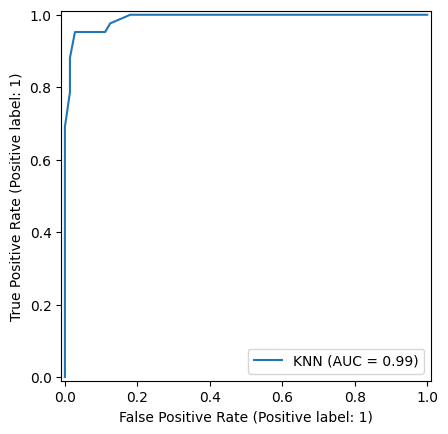

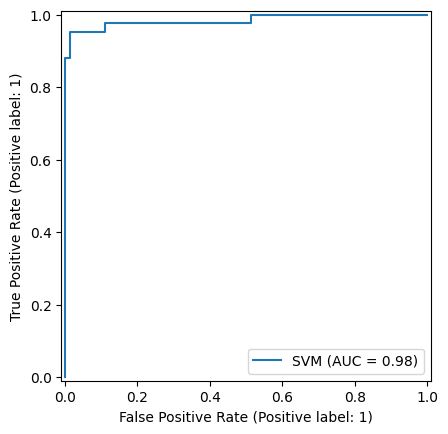

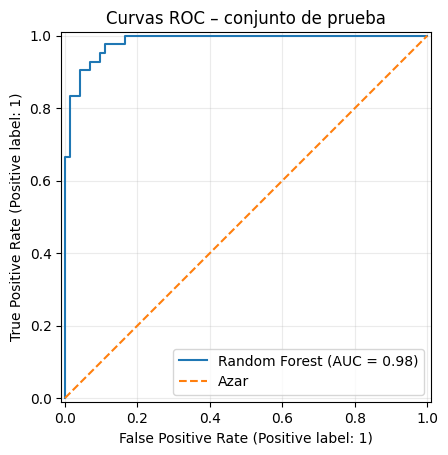

In [ ]:
from sklearn.metrics import RocCurveDisplay
plt.figure(figsize=(8,6))
for nombre, (pred, proba) in predicciones.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=nombre)
plt.plot([0,1],[0,1], linestyle='--', label='Azar')
plt.title('Curvas ROC – conjunto de prueba')
plt.grid(alpha=.25); plt.legend(); plt.show()

## 7. Matrices de confusión

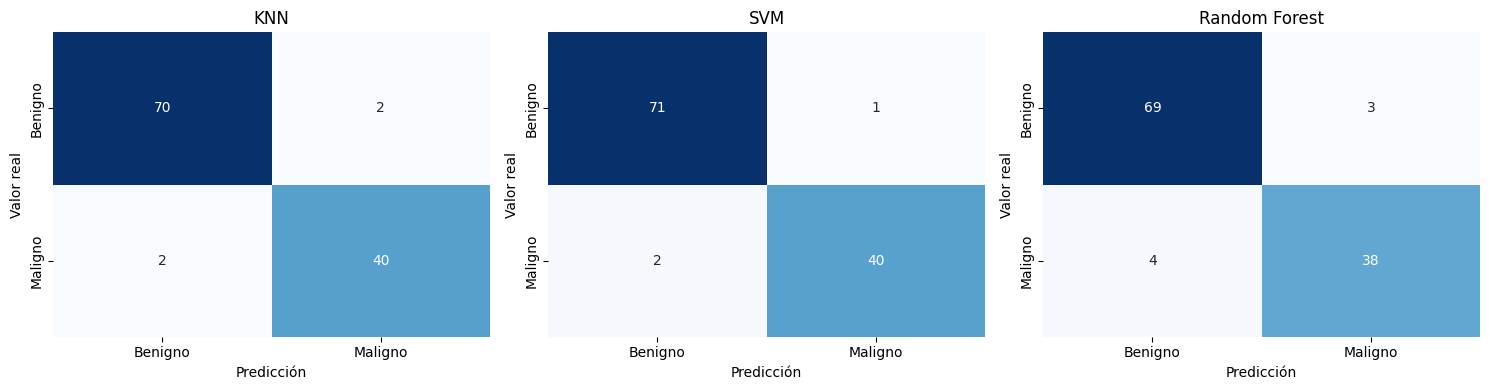

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, (nombre, (pred, proba)) in zip(axes, predicciones.items()):
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(nombre); ax.set_xlabel('Predicción'); ax.set_ylabel('Valor real')
    ax.set_xticklabels(['Benigno','Maligno']); ax.set_yticklabels(['Benigno','Maligno'])
plt.tight_layout(); plt.show()

## 8. Selección del modelo
Para este problema no basta con maximizar accuracy: los falsos negativos pueden ser especialmente costosos. Se revisa el recall junto con precisión, especificidad, F1 y AUC-ROC. La elección final debe justificarse con el comportamiento conjunto de las métricas y las limitaciones del dataset.

In [ ]:
ganador_accuracy = comparacion['Accuracy'].idxmax()
ganador_recall = comparacion['Recall (sensibilidad)'].idxmax()
ganador_f1 = comparacion['F1'].idxmax()
print('Mejor Accuracy:', ganador_accuracy)
print('Mejor Recall:', ganador_recall)
print('Mejor F1:', ganador_f1)
print('\nTabla ordenada por Recall:')
display(comparacion.sort_values('Recall (sensibilidad)', ascending=False).round(4))

Mejor Accuracy: SVM
Mejor Recall: KNN
Mejor F1: SVM

Tabla ordenada por Recall:


,Accuracy,Precision,Recall (sensibilidad),Especificidad,F1,AUC-ROC
Modelo,,,,,,
KNN,0.9649,0.9524,0.9524,0.9722,0.9524,0.9901
SVM,0.9737,0.9756,0.9524,0.9861,0.9639,0.9841
Random Forest,0.9386,0.9268,0.9048,0.9583,0.9157,0.9841


## 9. Conclusiones
Completa esta sección después de ejecutar el notebook y revisar la tabla y las matrices obtenidas.

- **Modelo con mejor sensibilidad:** anota el modelo que obtuvo el mayor recall.
- **Falsos negativos:** compara cuántos casos malignos fueron clasificados como benignos.
- **Equilibrio general:** considera F1 y AUC-ROC además de accuracy.
- **Consistencia con la aplicación:** el repositorio documenta SVM con kernel RBF como modelo seleccionado. Comprueba que la ejecución con el CSV del proyecto reproduce resultados equivalentes. Si utilizaste el dataset integrado de scikit-learn por falta del CSV, indica esa circunstancia y no presentes los resultados como una reproducción exacta del entrenamiento original.

**Nota ética:** este clasificador es un prototipo académico de apoyo al tamizaje; no sustituye la valoración de profesionales de salud ni una prueba diagnóstica.